# 04 · VLM 标注：用 Gemini 给街景打"地面体验"分（GreenPath）

**这一步做什么**：这是"老师"的部分。Gemini 看每张街景，按固定的打分规则，对 8 个维度各打 1–5 分，再按格子聚合，得到训练用的标签 **Y**。

| 维度 | 含义 |
|---|---|
| `traffic_intensity` | 机动车流量 |
| `quietness` | 安静程度 |
| `shade` | 骑行者头顶的树荫遮蔽 |
| `naturalness` | 自然感 |
| `scenic_appeal` | 整体景观吸引力 |
| `historic_character` | 历史风貌 |
| `liveliness` | 街道活力 |
| `visual_openness` | 视野开阔程度 |

| | 路径（相对数据根目录） |
|---|---|
| 输入：入选街景 | `processed/streetview.parquet`、`raw/mapillary/images/` |
| 输入：打分规则 | `prompts/{版本}.txt`（在项目目录里，不在数据目录） |
| 输出：每张图的分数（缓存） | `processed/labels_image.parquet` |
| 输出：**每个格子的标签 Y** | `processed/labels_cell.parquet` |
| 输出：标注元信息（模型、prompt 版本、花费） | `processed/labels_meta.json` |
| 输出：**图库（浏览所有图片和打分）** | `processed/labels_gallery.html`（用浏览器打开） |
| 输出：人工标注用的图片和表 | `processed/qa/human_images/`、`processed/qa/human_label_sheet.csv` |
| 输出：运行记录 | `runs/{时间戳}/04_labeling_manifest.json` |

**怎么用**
1. 先完成 Vertex AI 的准备（见第 2 节的清单），第 4 节"冒烟测试"通过后再往下。
2. 第 5 节 **prompt 试验台**：看 8 张图的打分和理由，不满意就改 `prompts/` 里的规则，**升一个版本号**（`v1` → `v2`），旧版本的标签不会被覆盖。
3. 第 6 节批量打分。结果按 `(图片, prompt 版本, 模型)` 缓存，**已经打过的不会重复调用，也不会重复花钱**，可以放心断点续跑或放大样本。

**会花钱**：每张图一次 Gemini 调用。第 4 节结束会估算每张图的费用，第 6 节结束会汇总实际花费。

## 1. 安装依赖（只在 Colab 里会执行）

In [ ]:
import sys, subprocess
if "google.colab" in sys.modules:      # 只有在 Colab 里才自动安装；本地环境请提前装好
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "google-genai", "pydantic", "h3>=4", "pandas", "pyarrow", "gcsfs", "matplotlib", "pillow", "scipy", "tqdm", "fsspec"], check=True)

## 2. 配置
**Vertex AI 准备清单（只需做一次）**
1. 在 GCP 控制台建项目，绑定账单账号（课程额度或试用额度）。
2. 启用 **Vertex AI API**。
3. 安装 gcloud CLI（Mac：`brew install --cask google-cloud-sdk`），运行 `gcloud auth application-default login`。
4. 在项目根目录的 `.env` 里加两行：`GOOGLE_CLOUD_PROJECT=你的项目ID`、`GOOGLE_CLOUD_LOCATION=us-central1`。
5. `MODEL` 填 Model Garden 里能用的 Gemini 型号；返回 404 说明这个型号在你的区域不可用。

**参数**
- `PROMPT_VERSION`：用哪一版打分规则（`prompts/{版本}.txt`）。改规则就升版本号。
- `THINKING_BUDGET`：部分 Gemini 型号默认会先"思考"，多花 token；`0` = 关闭（打分任务不需要），`None` = 不传这个参数（型号不支持时用）。
- `MIN_USABLE_IMAGES`：一个格子至少要有几张可用图才产出标签，不够的标为缺失（NaN），训练时跳过。
- `MAX_IMAGES`：本次最多打多少张新图（`None` = 全部）。第一次建议先设 50 左右试水。
- `THUMB_PX` / `GALLERY_MAX_IMAGES`：图库里缩略图的大小，以及最多放多少张。
- `PRICE_*`：每百万 token 的价格（美元），只用来估算花费。**请对照官方价格页核对**。

In [ ]:
PROMPT_VERSION = "v2"
PROMPT_DIR = "prompts"
MODEL = "gemini-2.5-flash"      # 以 Vertex AI Model Garden 里实际可用的型号为准
THINKING_BUDGET = 0             # 0 关闭思考；None 不传此参数

WORKERS = 8
MIN_USABLE_IMAGES = 2
MAX_IMAGES = None               # 例如 50：本次最多新打 50 张
SANDBOX_N = 8                   # prompt 试验台看几张图
QA_N = 150                      # 导出给人工标注的图片数
THUMB_PX = 480                  # 图库里缩略图的最长边（像素）
GALLERY_MAX_IMAGES = 1000       # 图库最多放多少张；None = 全部
SEED = 42

PRICE_IN_PER_M = 0.30           # 美元 / 百万输入 token（请核对官方价格）
PRICE_OUT_PER_M = 2.50          # 美元 / 百万输出 token（请核对官方价格）

STORAGE = "local"                              # "local" | "gcs" | "drive"
GCS_ROOT = "gs://greenpath-data"
DRIVE_ROOT = "/content/drive/MyDrive/greenpath-data"
LOCAL_ROOT = "./data"

## 3. 连接存储，读取项目配置

In [ ]:
import os, io, json, datetime
import fsspec
import pandas as pd

STORAGE_OPTS = {}
if STORAGE == "gcs":
    try:
        from google.colab import auth
        auth.authenticate_user()                 # Colab 里登录；本地请先 gcloud auth application-default login
    except ImportError:
        pass
    ROOT = GCS_ROOT
    STORAGE_OPTS = {"token": "google_default"}
    fs = fsspec.filesystem("gcs", **STORAGE_OPTS)
elif STORAGE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = DRIVE_ROOT
    fs = fsspec.filesystem("file")
else:
    ROOT = os.environ.get("GREENPATH_ROOT", LOCAL_ROOT)   # 以后容器里用环境变量指定数据目录
    fs = fsspec.filesystem("file")

def path(*parts):
    # 拼出数据根目录下的完整路径，例如 path("processed", "cells.parquet")
    return "/".join([ROOT.rstrip("/"), *parts])

def makedirs(p):
    if STORAGE != "gcs":            # GCS 没有真正的目录，不需要创建
        os.makedirs(p, exist_ok=True)

def read_parquet(p):
    return pd.read_parquet(p, storage_options=STORAGE_OPTS or None)

def write_parquet(df, p):
    df.to_parquet(p, index=False, storage_options=STORAGE_OPTS or None)

def write_manifest(manifest, name):
    run_ts = datetime.datetime.utcnow().strftime("%Y-%m-%dT%H-%M")
    makedirs(path("runs", run_ts))
    with fs.open(path("runs", run_ts, name), "w") as f:
        json.dump(manifest, f, indent=2, ensure_ascii=False)
    return manifest

try:                                          # 图里的中文用系统自带的中文字体显示
    import matplotlib
    matplotlib.rcParams["font.sans-serif"] = ["PingFang SC", "Heiti SC", "Arial Unicode MS", "Noto Sans CJK SC",
                                              "Microsoft YaHei", "SimHei", "DejaVu Sans"]
    matplotlib.rcParams["axes.unicode_minus"] = False
except ImportError:
    pass

now_iso = lambda: datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"
print("数据根目录:", ROOT)

数据根目录: ./data


In [ ]:
import numpy as np, hashlib, random, threading, time
from concurrent.futures import ThreadPoolExecutor, as_completed
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

def load_dotenv_file(name=".env"):
    # 从当前目录向上找 .env，把里面的 KEY=VALUE 读进环境变量（已经设置过的环境变量优先）
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, name)
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8"):
                line = line.strip()
                if line and not line.startswith("#") and "=" in line:
                    k, v = line.split("=", 1)
                    os.environ.setdefault(k.strip(), v.strip().strip("\"'"))
            return p
        if os.path.dirname(d) == d:
            return None
        d = os.path.dirname(d)

load_dotenv_file()
PROJECT = os.environ.get("GOOGLE_CLOUD_PROJECT")
LOCATION = os.environ.get("GOOGLE_CLOUD_LOCATION", "us-central1")
assert PROJECT, "没找到 GOOGLE_CLOUD_PROJECT：请在 .env 里加 GOOGLE_CLOUD_PROJECT=你的项目ID（见第 2 节清单）"

DIMS = ["traffic_intensity", "quietness", "shade", "naturalness",
        "scenic_appeal", "historic_character", "liveliness", "visual_openness"]

sv = read_parquet(path("processed", "streetview.parquet"))
if "downloaded" in sv:                                  # 01 里下载失败的图没有文件，跳过
    sv = sv[sv.downloaded.astype(bool)].reset_index(drop=True)
cells = read_parquet(path("processed", "cells.parquet"))
print(f"项目 {PROJECT} · 区域 {LOCATION} · 模型 {MODEL}")
print(f"待处理：{len(sv)} 张街景，{sv.cell_id.nunique()} 个格子")

项目 organic-victory-508017-v9 · 区域 us-central1 · 模型 gemini-2.5-flash
待处理：4421 张街景，1126 个格子


## 4. 连接 Vertex AI + 冒烟测试
`call_model` 是**整个 notebook 里唯一直接调用 Gemini 的地方**。冒烟测试给一张图打分，失败时会告诉你是哪一类问题：

| 错误 | 常见原因 |
|---|---|
| 401 | 没登录：运行 `gcloud auth application-default login` |
| 403 | 项目没启用 Vertex AI API、没绑定账单、或账号没有权限 |
| 404 | 这个型号在这个区域不可用：换 `MODEL` 或 `GOOGLE_CLOUD_LOCATION` |
| 400 | 参数不被支持：先把 `THINKING_BUDGET` 改成 `None` 试试 |
| 429 | 请求太快（配额）：调低 `WORKERS` |

In [ ]:
import json
from pydantic import BaseModel
from google import genai
from google.genai import types, errors as genai_errors

class Scores(BaseModel):
    traffic_intensity: int
    quietness: int
    shade: int
    naturalness: int
    scenic_appeal: int
    historic_character: int
    liveliness: int
    visual_openness: int

class ImageLabel(BaseModel):
    usable: bool
    unusable_reason: str
    scores: Scores
    rationale: str

PROMPT = open(os.path.join(PROMPT_DIR, f"{PROMPT_VERSION}.txt"), encoding="utf-8").read()
PROMPT_SHA = hashlib.sha256(PROMPT.encode()).hexdigest()[:12]

client = genai.Client(vertexai=True, project=PROJECT, location=LOCATION)

def call_model(img_bytes):
    # 返回 (回复的 JSON 文本, 输入 token 数, 输出 token 数)
    cfg = dict(temperature=0.0, response_mime_type="application/json",
               response_schema=ImageLabel, max_output_tokens=2048)
    if THINKING_BUDGET is not None:
        cfg["thinking_config"] = types.ThinkingConfig(thinking_budget=THINKING_BUDGET)
    resp = client.models.generate_content(
        model=MODEL,
        contents=[types.Part.from_bytes(data=img_bytes, mime_type="image/jpeg"), PROMPT],
        config=types.GenerateContentConfig(**cfg))
    u = resp.usage_metadata
    tin = (u.prompt_token_count or 0) if u else 0
    tout = ((u.candidates_token_count or 0) + (getattr(u, "thoughts_token_count", 0) or 0)) if u else 0
    return resp.text, tin, tout

FATAL_HINTS = {
    400: "参数不被支持：先把 THINKING_BUDGET 改成 None 试试",
    401: "没登录：运行 gcloud auth application-default login",
    403: "项目没启用 Vertex AI API、没绑定账单、或账号没有权限",
    404: "这个型号在这个区域不可用：换 MODEL 或 GOOGLE_CLOUD_LOCATION",
}

class FatalAPIError(RuntimeError):
    pass

def check_label(label):
    sc = label.scores.model_dump()
    if label.usable:
        bad = {k: v for k, v in sc.items() if not 1 <= v <= 5}
        if bad:
            raise ValueError(f"可用的图片分数必须在 1–5 之间：{bad}")
    else:
        sc = {k: 0 for k in sc}
    return sc

def score_image(image_id, rel_path, tries=5):
    with fs.open(path(rel_path), "rb") as f:
        data = f.read()
    last = None
    for k in range(tries):
        try:
            text, tin, tout = call_model(data)
            label = ImageLabel.model_validate_json(text)
            sc = check_label(label)
            return {"image_id": image_id, "prompt_version": PROMPT_VERSION, "prompt_sha": PROMPT_SHA,
                    "model": MODEL, "usable": bool(label.usable),
                    "unusable_reason": label.unusable_reason, **sc,
                    "rationale": label.rationale, "input_tokens": tin, "output_tokens": tout,
                    "scored_at": now_iso()}
        except genai_errors.APIError as e:
            if e.code in FATAL_HINTS:
                raise FatalAPIError(f"Vertex AI 返回 {e.code}：{FATAL_HINTS[e.code]}\n原始信息：{str(e)[:300]}")
            last = e
            time.sleep(min(60, 2 ** k + random.random()))      # 429 / 5xx：退避重试
        except ValueError as e:                                  # 返回的 JSON 不合格式
            last = e
            time.sleep(1)
    raise RuntimeError(f"重试 {tries} 次仍失败：{last!r}"[:300])

def cost_usd(tin, tout):
    return tin / 1e6 * PRICE_IN_PER_M + tout / 1e6 * PRICE_OUT_PER_M

first = sv.iloc[0]
row = score_image(first.image_id, first.image_path)
print(json.dumps({k: row[k] for k in ["usable", "unusable_reason", *DIMS, "rationale"]}, ensure_ascii=False, indent=2))
print(f"这张图：输入 {row['input_tokens']} / 输出 {row['output_tokens']} token，约 ${cost_usd(row['input_tokens'], row['output_tokens']):.5f}"
      f" → 估算 {len(sv)} 张约 ${cost_usd(row['input_tokens'], row['output_tokens']) * len(sv):.2f}")

{
  "usable": true,
  "unusable_reason": "",
  "traffic_intensity": 3,
  "quietness": 3,
  "shade": 3,
  "naturalness": 3,
  "scenic_appeal": 3,
  "historic_character": 3,
  "liveliness": 3,
  "visual_openness": 3,
  "rationale": "The street has some traffic, a mix of buildings and trees, and a moderate view, creating an ordinary urban cycling experience."
}
这张图：输入 2236 / 输出 137 token，约 $0.00101 → 估算 4421 张约 $4.48


## 5. Prompt 试验台
随机取 `SANDBOX_N` 张图，显示图片、8 个分数和 Gemini 给的理由。**这里的结果不会写入缓存**，专门用来改打分规则。
看什么：
- 分数是不是总挤在 3？（挤在中间说明锚点不够有区分度）
- 理由和你自己的判断一致吗？
- 该标"不可用"的图（车内、模糊）有没有被标出来？

不满意就改 `prompts/{版本}.txt`，**升一个版本号**（改 `PROMPT_VERSION`），再重跑第 4 节和这一节。

试验台:   0%|          | 0/8 [00:00<?, ?it/s]

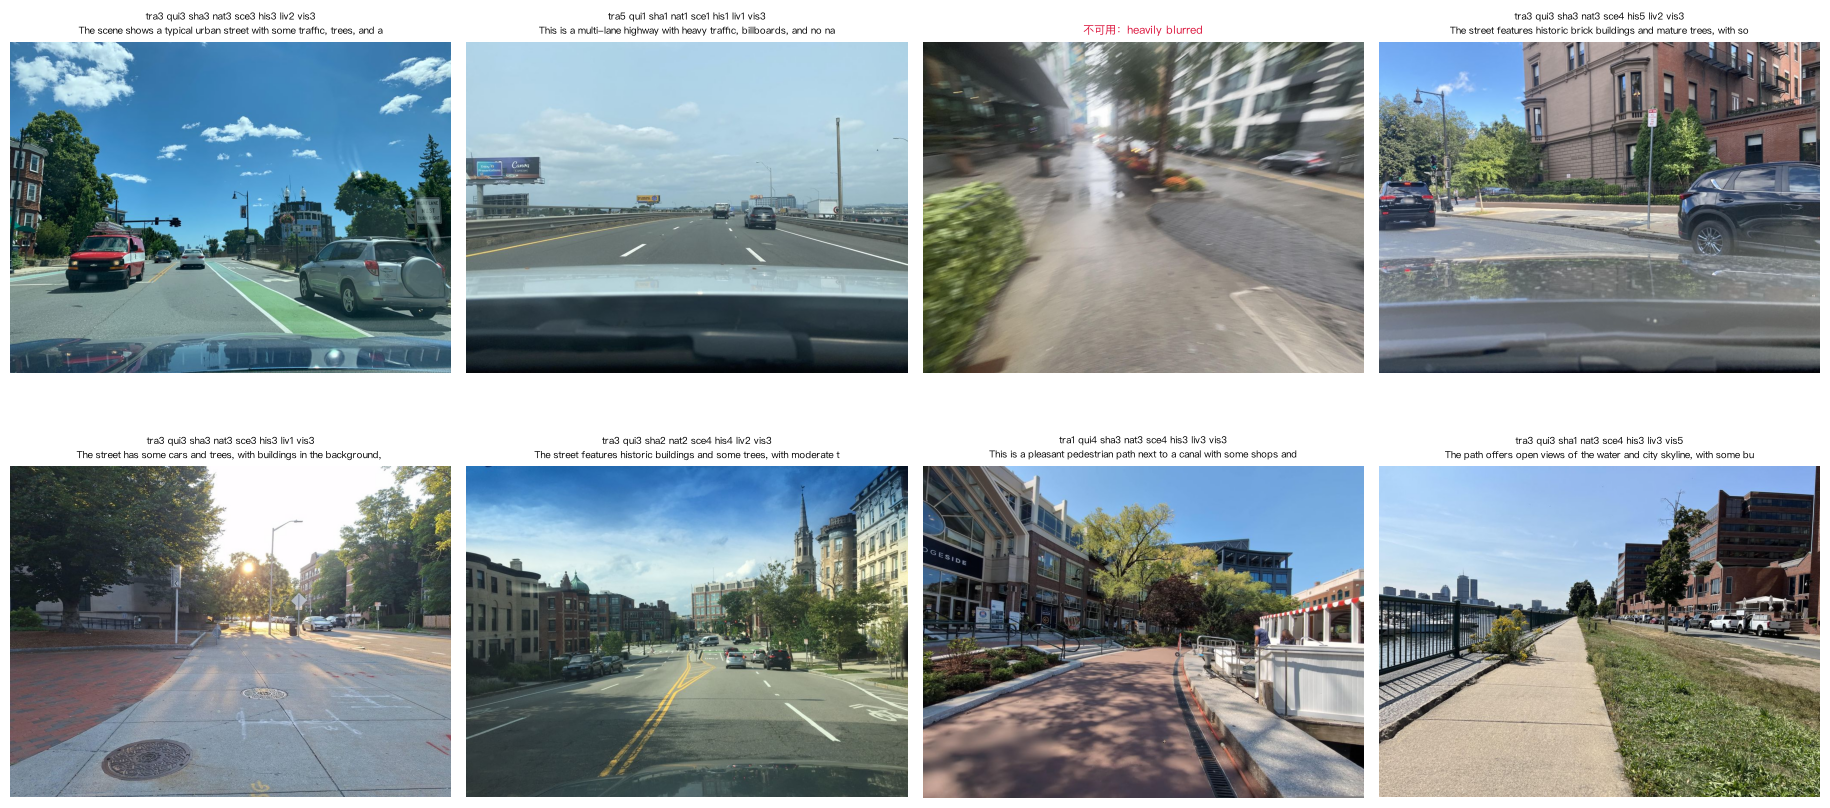

In [ ]:
sample = sv.sample(n=min(SANDBOX_N, len(sv)), random_state=SEED)
items = list(sample.itertuples())

def try_score(r):
    try:
        return r, score_image(r.image_id, r.image_path)
    except Exception as e:
        print("  失败：", r.image_id, repr(e)[:150])
        return None

with ThreadPoolExecutor(max_workers=WORKERS) as ex:                # 并行调用，8 张图约十秒
    rows = [x for x in tqdm(ex.map(try_score, items), total=len(items), desc="试验台") if x]

ncol = 4; nrow = max(int(np.ceil(len(rows) / ncol)), 1)
fig, axes = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, 4.6 * nrow))
for ax in np.atleast_1d(axes).ravel():
    ax.axis("off")
for ax, (r, lab) in zip(np.atleast_1d(axes).ravel(), rows):
    with fs.open(path(r.image_path), "rb") as f:
        ax.imshow(Image.open(f))
    if lab["usable"]:
        s = " ".join(f"{d[:3]}{lab[d]}" for d in DIMS)
        ax.set_title(f"{s}\n{lab['rationale'][:70]}", fontsize=7)
    else:
        ax.set_title(f"不可用：{lab['unusable_reason'][:60]}", fontsize=8, color="crimson")
plt.tight_layout(); plt.show()

## 6. 批量打分
- 只处理**还没有缓存**的图（缓存键：图片 + prompt 版本 + 模型）。
- 用 `WORKERS` 个线程并发；每 50 张存一次盘，中途中断（甚至 Ctrl-C）不会丢结果。
- 单张失败只记录，不中断整批；**遇到认证 / 权限 / 型号这类系统性错误会立刻停下**，避免白白调用几百次。

In [ ]:
from concurrent.futures import ThreadPoolExecutor, as_completed

LABELS_REL = "processed/labels_image.parquet"
LABEL_COLS = ["image_id", "prompt_version", "prompt_sha", "model", "usable", "unusable_reason", *DIMS,
              "rationale", "input_tokens", "output_tokens", "scored_at"]

def load_cache():
    p = path(LABELS_REL)
    return read_parquet(p) if fs.exists(p) else pd.DataFrame(columns=LABEL_COLS)

cache = load_cache()
done = set(cache[(cache.prompt_version == PROMPT_VERSION) & (cache.model == MODEL)].image_id)
todo = sv[~sv.image_id.isin(done)]
if MAX_IMAGES:
    todo = todo.head(MAX_IMAGES)
print(f"缓存里已有 {len(done)} 张；这次要新打 {len(todo)} 张")

new_rows, errors, abort = [], {}, threading.Event()

def save_progress():
    global cache
    if new_rows:
        cache = pd.concat([cache, pd.DataFrame(new_rows, columns=LABEL_COLS)], ignore_index=True) \
                  .drop_duplicates(["image_id", "prompt_version", "model"], keep="last")
        write_parquet(cache, path(LABELS_REL))
        new_rows.clear()

def work(r):
    if abort.is_set():
        return None
    return score_image(r.image_id, r.image_path)

fatal = None
try:
    with ThreadPoolExecutor(max_workers=WORKERS) as ex:
        futs = {ex.submit(work, r): r for r in todo.itertuples()}
        for k, fut in enumerate(tqdm(as_completed(futs), total=len(futs), desc="打分"), 1):
            r = futs[fut]
            try:
                row = fut.result()
                if row:
                    new_rows.append(row)
            except FatalAPIError as e:
                fatal = e; abort.set()
            except Exception as e:
                errors[r.image_id] = repr(e)[:200]
            if k % 50 == 0:
                save_progress()
finally:
    save_progress()

mine = cache[(cache.prompt_version == PROMPT_VERSION) & (cache.model == MODEL)]
print(f"现在缓存里有 {len(mine)} 张（可用 {int(mine.usable.sum())} 张，不可用 {int((~mine.usable.astype(bool)).sum())} 张）；本次失败 {len(errors)} 张")
tin, tout = int(mine.input_tokens.sum()), int(mine.output_tokens.sum())
print(f"累计 token：输入 {tin:,} / 输出 {tout:,}，估算累计花费约 ${cost_usd(tin, tout):.3f}")
if errors:
    print("失败样例：", list(errors.items())[:3])
if fatal:
    raise fatal

缓存里已有 4421 张；这次要新打 0 张


打分: 0it [00:00, ?it/s]

现在缓存里有 4421 张（可用 4340 张，不可用 81 张）；本次失败 0 张
累计 token：输入 10,505,072 / 输出 557,698，估算累计花费约 $4.546


## 7. 按格子聚合 → 标签 Y
- 只用**可用**的图；每个格子对每个维度取均值，并记录标准差（同一格子几张图分歧大不大）和张数。
- 归一化到 0–1：`(分数 − 1) / 4`。
- 可用图少于 `MIN_USABLE_IMAGES` 张的格子，标签标为 `NaN`（缺失）：训练时用带掩码的损失跳过，不当作 0。

In [ ]:
mine = cache[(cache.prompt_version == PROMPT_VERSION) & (cache.model == MODEL)].copy()
mine["usable"] = mine.usable.astype(bool)
for d in DIMS:
    mine[d] = pd.to_numeric(mine[d])
lab = mine.merge(sv[["image_id", "cell_id", "h3_index"]], on="image_id", how="inner")
ok = lab[lab.usable]

g = ok.groupby(["cell_id", "h3_index"])
agg = g[DIMS].mean().add_suffix("_mean").join(g[DIMS].std(ddof=0).add_suffix("_std")).join(g.size().rename("n_usable")).reset_index()
labels_cell = cells[["cell_id", "h3_index"]].merge(agg, on=["cell_id", "h3_index"], how="left")
labels_cell["n_images"] = labels_cell.cell_id.map(sv.groupby("cell_id").size()).fillna(0).astype(int)
labels_cell["n_usable"] = labels_cell.n_usable.fillna(0).astype(int)
enough = labels_cell.n_usable >= MIN_USABLE_IMAGES
for d in DIMS:
    labels_cell[d] = ((labels_cell[f"{d}_mean"] - 1) / 4).where(enough)          # 归一化到 0–1
    labels_cell[f"{d}_std"] = (labels_cell[f"{d}_std"] / 4).where(enough)
labels_cell = labels_cell[["cell_id", "h3_index", "n_images", "n_usable", *DIMS, *[f"{d}_std" for d in DIMS]]]
labels_cell["prompt_version"] = PROMPT_VERSION
labels_cell["model"] = MODEL
write_parquet(labels_cell, path("processed", "labels_cell.parquet"))

meta = {"model": MODEL, "prompt_version": PROMPT_VERSION, "prompt_sha": PROMPT_SHA, "location": LOCATION,
        "thinking_budget": THINKING_BUDGET, "temperature": 0.0, "min_usable_images": MIN_USABLE_IMAGES,
        "images_scored": int(len(mine)), "images_usable": int(mine.usable.sum()),
        "input_tokens": int(mine.input_tokens.sum()), "output_tokens": int(mine.output_tokens.sum()),
        "est_cost_usd": round(cost_usd(int(mine.input_tokens.sum()), int(mine.output_tokens.sum())), 4),
        "cells_total": int(len(labels_cell)), "cells_labeled": int(enough.sum()), "created_at": now_iso()}
with fs.open(path("processed", "labels_meta.json"), "w") as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)
print(f"labels_cell.parquet：{len(labels_cell)} 个格子，其中 {int(enough.sum())} 个有标签（可用图 ≥ {MIN_USABLE_IMAGES}）")
labels_cell[DIMS].describe().T[["count", "mean", "std", "min", "max"]].round(2)

labels_cell.parquet：1126 个格子，其中 1116 个有标签（可用图 ≥ 2）


,count,mean,std,min,max
traffic_intensity,1116.0,0.55,0.22,0.0,1.00
quietness,1116.0,0.41,0.20,0.0,1.00
shade,1116.0,0.26,0.25,0.0,1.00
naturalness,1116.0,0.27,0.21,0.0,1.00
scenic_appeal,1116.0,0.44,0.22,0.0,1.00
historic_character,1116.0,0.38,0.28,0.0,1.00
liveliness,1116.0,0.21,0.18,0.0,0.75
visual_openness,1116.0,0.50,0.11,0.0,1.00


## 8. 图库：浏览所有图片和详细打分
生成一个**单文件 HTML**（`processed/labels_gallery.html`），用浏览器直接打开，不需要 kernel：
- 每张图一张卡片：缩略图（嵌入的 `THUMB_PX` 像素小图，**点击打开原图**）、8 个维度的分数条、Gemini 的理由、所属格子、拍摄时间、朝向。
- **筛选**：只看可用 / 不可用；按格子搜索；按某个维度的分数范围筛（例如"树荫 = 1"的所有图，看是不是真的没树）。
- **排序**：按某个维度高→低或低→高；按格子分组，同一地点的几张图并排，看它们的分歧大不大。
- **版本对比**：同一张图如果在别的 prompt 版本或模型下也打过分，卡片里可以展开对比。
- 因为缩略图是嵌进去的，这个文件可以直接发给组员；点击看原图要求 HTML 和 `data/` 目录在同一台机器的原位置（本地存储模式）。

`GALLERY_MAX_IMAGES`：最多放多少张（超过就随机取一部分）。每张缩略图约 30 KB，1,000 张约 30 MB，浏览器还能流畅打开；`None` = 全部。

In [ ]:
import base64, io as _io
from concurrent.futures import ThreadPoolExecutor

GALLERY_REL = "processed/labels_gallery.html"
SHORT = {"traffic_intensity": "Traffic", "quietness": "Quiet", "shade": "Shade", "naturalness": "Nature",
         "scenic_appeal": "Scenic", "historic_character": "Historic", "liveliness": "Lively", "visual_openness": "Open"}

def make_thumb(rel_path):
    with fs.open(path(rel_path), "rb") as f:
        im = Image.open(f).convert("RGB")
    im.thumbnail((THUMB_PX, THUMB_PX))
    buf = _io.BytesIO(); im.save(buf, "JPEG", quality=70)
    return "data:image/jpeg;base64," + base64.b64encode(buf.getvalue()).decode()

allv = cache.copy()
allv["usable"] = allv.usable.astype(bool)
is_cur = (allv.prompt_version == PROMPT_VERSION) & (allv.model == MODEL)
cur = allv[is_cur].merge(sv[["image_id", "cell_id", "image_path", "captured_at", "compass"]], on="image_id", how="inner")
if GALLERY_MAX_IMAGES and len(cur) > GALLERY_MAX_IMAGES:
    cur = cur.sample(n=GALLERY_MAX_IMAGES, random_state=SEED)
cur = cur.sort_values(["cell_id", "image_id"]).reset_index(drop=True)

others = {}
for r in allv[~is_cur].itertuples():
    tag = r.prompt_version + ("" if r.model == MODEL else f" · {r.model}")
    others.setdefault(r.image_id, []).append({"n": tag, "u": bool(r.usable), "s": [int(getattr(r, d)) for d in DIMS],
                                              "r": r.rationale})

with ThreadPoolExecutor(max_workers=WORKERS) as ex:
    thumbs = list(tqdm(ex.map(make_thumb, cur.image_path), total=len(cur), desc="生成缩略图"))

records = []
for r, th in zip(cur.itertuples(), thumbs):
    records.append({"id": r.image_id, "c": r.cell_id[-8:], "cf": r.cell_id, "t": th, "h": "../" + r.image_path,
                    "u": bool(r.usable), "x": r.unusable_reason, "s": {d: int(getattr(r, d)) for d in DIMS},
                    "r": r.rationale, "d": str(r.captured_at)[:10], "a": round(float(r.compass)),
                    "v": others.get(r.image_id, [])})

GALLERY_HTML = r"""<!doctype html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>GreenPath Label Gallery</title>
<style>
:root{--bg:#f6f6f3;--card:#fff;--ink:#1c1c1a;--muted:#6a6a64;--line:#e1e1da;--accent:#2f7d57;--bad:#b3392f;--track:#ececE6}
@media (prefers-color-scheme:dark){:root{--bg:#161615;--card:#222220;--ink:#ecece7;--muted:#9a9a92;--line:#363631;--accent:#5bbb89;--bad:#e8786d;--track:#33332f}}
*{box-sizing:border-box}
body{margin:0;background:var(--bg);color:var(--ink);font:14px/1.45 -apple-system,BlinkMacSystemFont,"Segoe UI","PingFang SC","Microsoft YaHei",sans-serif}
header{position:sticky;top:0;z-index:5;background:var(--bg);border-bottom:1px solid var(--line);padding:12px 16px}
h1{font-size:16px;margin:0 0 8px;font-weight:600}
.ctl{display:flex;flex-wrap:wrap;gap:8px 14px;align-items:center}
.ctl label{display:flex;gap:6px;align-items:center;color:var(--muted);font-size:13px}
select,input{font:inherit;color:var(--ink);background:var(--card);border:1px solid var(--line);border-radius:6px;padding:4px 8px}
input[type=number]{width:56px}input[type=text]{width:120px}
button{font:inherit;color:var(--ink);background:var(--card);border:1px solid var(--line);border-radius:6px;padding:4px 12px;cursor:pointer}
button:disabled{opacity:.4;cursor:default}
#info{color:var(--muted);font-size:13px;margin-top:8px}
main{padding:16px;display:grid;grid-template-columns:repeat(auto-fill,minmax(300px,1fr));gap:14px}
.grp{grid-column:1/-1;font-weight:600;padding:6px 0 0;border-bottom:1px solid var(--line)}
.grp span{color:var(--muted);font-weight:400;margin-left:8px;font-size:13px}
.card{background:var(--card);border:1px solid var(--line);border-radius:10px;overflow:hidden;display:flex;flex-direction:column}
.card.bad{border-color:var(--bad)}
.card img{width:100%;height:210px;object-fit:cover;display:block;background:var(--track)}
.body{padding:10px 12px 12px}
.meta{display:flex;justify-content:space-between;color:var(--muted);font-size:12px;margin-bottom:6px}
.row{display:grid;grid-template-columns:34px 1fr 16px;gap:8px;align-items:center;margin:3px 0;font-size:13px}
.bar{height:8px;background:var(--track);border-radius:4px;overflow:hidden}.bar i{display:block;height:100%;background:var(--accent)}
.row b{text-align:right}
.why{margin-top:8px;color:var(--muted);font-size:12.5px}
.warn{color:var(--bad);font-weight:600}
details{margin-top:8px;font-size:12px;color:var(--muted)}
details table{border-collapse:collapse;margin-top:4px}details td{padding:1px 6px 1px 0}
.diff{color:var(--bad);font-weight:600}
@media (max-width:520px){main{padding:12px;grid-template-columns:1fr}}
</style></head><body>
<header>
<h1>GreenPath Label Gallery <small style="color:var(--muted);font-weight:400">__META__</small></h1>
<div class="ctl">
<label>Status<select id="fu"><option value="all">All</option><option value="1">Usable only</option><option value="0">Unusable only</option></select></label>
<label>Cell<input type="text" id="fc" placeholder="cell_id fragment"></label>
<label>Dimension<select id="fd"><option value="">No filter</option></select>
 <input type="number" id="lo" min="1" max="5" value="1">–<input type="number" id="hi" min="1" max="5" value="5"></label>
<label>Sort<select id="so"></select></label>
<label><input type="checkbox" id="gp"> Group by cell</label>
<label>Per page<select id="ps"><option>24</option><option selected>48</option><option>96</option></select></label>
<span><button id="pv">Prev</button> <span id="pg"></span> <button id="nx">Next</button></span>
</div><div id="info"></div></header>
<main id="main"></main>
<script>
const DATA=__DATA__;const DIMS=__DIMS__;const LABEL=__LABEL__;
const $=id=>document.getElementById(id);
const esc=s=>String(s).replace(/[&<>"]/g,c=>({"&":"&amp;","<":"&lt;",">":"&gt;",'"':"&quot;"}[c]));
let page=0,rows=[];
DIMS.forEach(k=>{$("fd").add(new Option(LABEL[k],k));
 $("so").add(new Option(LABEL[k]+" high→low","h:"+k));$("so").add(new Option(LABEL[k]+" low→high","l:"+k));});
$("so").insertBefore(new Option("Cell (default)","cell"),$("so").firstChild);$("so").value="cell";
function apply(){
 const u=$("fu").value,c=$("fc").value.trim().toLowerCase(),d=$("fd").value,lo=+$("lo").value,hi=+$("hi").value;
 rows=DATA.filter(x=>(u==="all"||(u==="1")===x.u)&&(!c||x.cf.toLowerCase().includes(c))&&(!d||(x.u&&x.s[d]>=lo&&x.s[d]<=hi)));
 const so=$("so").value;
 if(so.includes(":")){const [m,k]=so.split(":");rows.sort((a,b)=>(m==="h"?-1:1)*((a.u?a.s[k]:99*(m==="h"?-1:1))-(b.u?b.s[k]:99*(m==="h"?-1:1))));}
 else rows.sort((a,b)=>a.cf<b.cf?-1:a.cf>b.cf?1:(a.id<b.id?-1:1));
 if($("gp").checked&&so.includes(":"))rows.sort((a,b)=>a.cf<b.cf?-1:a.cf>b.cf?1:0);
 page=0;render();}
function card(x){
 const bars=DIMS.map(k=>`<div class="row"><span>${LABEL[k]}</span><span class="bar"><i style="width:${x.u?x.s[k]*20:0}%"></i></span><b>${x.u?x.s[k]:"–"}</b></div>`).join("");
 const why=x.u?esc(x.r):`<span class="warn">Unusable: </span>${esc(x.x)}`;
 let ver="";
 if(x.v.length){ver=`<details><summary>Other versions (${x.v.length})</summary><table><tr><td></td>${DIMS.map(k=>`<td>${LABEL[k]}</td>`).join("")}</tr>`+
  [{n:"current",u:x.u,s:DIMS.map(k=>x.s[k])}].concat(x.v).map(v=>`<tr><td>${esc(v.n)}</td>${v.s.map((s,i)=>{const cur=x.s[DIMS[i]];const df=v.u&&x.u&&Math.abs(s-cur)>=2;return `<td class="${df?"diff":""}">${v.u?s:"–"}</td>`}).join("")}</tr>`).join("")+`</table></details>`;}
 return `<div class="card ${x.u?"":"bad"}"><a href="${esc(x.h)}" target="_blank" title="Click to open the original image"><img src="${x.t}" loading="lazy" alt=""></a>
 <div class="body"><div class="meta"><span>${esc(x.c)} · ${esc(x.id)}</span><span>${esc(x.d)} · ${x.a}°</span></div>${bars}<div class="why">${why}</div>${ver}</div></div>`;}
function render(){
 const ps=+$("ps").value,np=Math.max(1,Math.ceil(rows.length/ps));page=Math.min(page,np-1);
 const cells={};rows.forEach(x=>{(cells[x.cf]=cells[x.cf]||[]).push(x)});
 const grouped=$("gp").checked;let html="",last=null;
 rows.slice(page*ps,(page+1)*ps).forEach(x=>{
  if(grouped&&x.cf!==last){const g=cells[x.cf];html+=`<div class="grp">${esc(x.cf)}<span>${g.length} images · ${g.filter(y=>y.u).length} usable</span></div>`;last=x.cf;}
  html+=card(x);});
 $("main").innerHTML=html||'<p style="grid-column:1/-1;color:var(--muted)">No images match the filters</p>';
 $("pg").textContent=`Page ${page+1} / ${np}`;$("pv").disabled=page===0;$("nx").disabled=page>=np-1;
 const nu=rows.filter(x=>x.u).length;
 $("info").textContent=`${rows.length} images match (${nu} usable, ${rows.length-nu} unusable) of ${DATA.length} total, ${new Set(rows.map(x=>x.cf)).size} cells`;
 window.scrollTo(0,0);}
["fu","fc","fd","lo","hi","so","gp","ps"].forEach(i=>$(i).addEventListener("input",apply));
$("pv").onclick=()=>{page--;render()};$("nx").onclick=()=>{page++;render()};
apply();
</script></body></html>"""

gallery_meta = f"{PROMPT_VERSION} · {MODEL} · {THUMB_PX}px thumbnails, click to open the original"
html = (GALLERY_HTML.replace("__META__", gallery_meta)
        .replace("__DIMS__", json.dumps(DIMS)).replace("__LABEL__", json.dumps(SHORT, ensure_ascii=False))
        .replace("__DATA__", json.dumps(records, ensure_ascii=True).replace("</", "<\\/")))
with fs.open(path(GALLERY_REL), "wb") as f:
    f.write(html.encode("utf-8"))
size_mb = len(html.encode()) / 1e6
print(f"图库已生成：{GALLERY_REL}（{len(records)} 张，{size_mb:.1f} MB）")
print("用浏览器打开：", os.path.abspath(path(GALLERY_REL)) if STORAGE != "gcs" else path(GALLERY_REL))

生成缩略图:   0%|          | 0/1000 [00:00<?, ?it/s]

图库已生成：processed/labels_gallery.html（1000 张，35.8 MB）
用浏览器打开： /Users/wxz/code/course/ac215/final/data/processed/labels_gallery.html


## 9. 质检（1）：分数是不是都挤在中间？
VLM 打绝对分的常见毛病是**分数扎堆在 3**，没有区分度。下面看每个维度在可用图上的分布，并给出提醒：
- 某一档占比超过 60%，或标准差低于 0.6，说明这个维度区分度差，需要改锚点、加例子，或者考虑改成两两比较。
- "格子内标准差"是同一个格子里几张图的平均分歧，越小说明同一地点的几张图评价越一致。

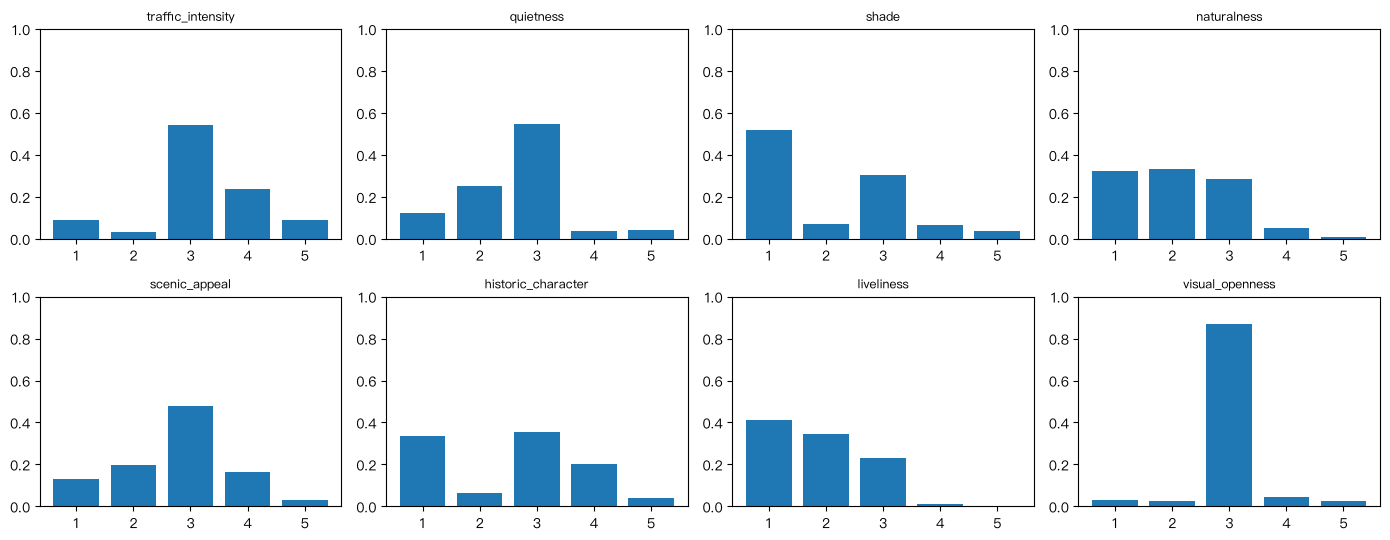

,均值,标准差,最大一档占比,格子内标准差,提醒
维度,,,,,
traffic_intensity,3.21,0.98,0.54,0.28,
quietness,2.62,0.89,0.55,0.25,
shade,2.03,1.20,0.52,0.44,
naturalness,2.08,0.93,0.33,0.29,
scenic_appeal,2.77,0.98,0.48,0.29,
historic_character,2.54,1.25,0.36,0.38,
liveliness,1.84,0.81,0.41,0.28,
visual_openness,3.00,0.55,0.87,0.15,⚠ 区分度低


In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5))
rows = []
for ax, d in zip(axes.ravel(), DIMS):
    vc = ok[d].value_counts(normalize=True).reindex([1, 2, 3, 4, 5]).fillna(0)
    ax.bar(vc.index, vc.values); ax.set_title(d, fontsize=9); ax.set_ylim(0, 1); ax.set_xticks([1, 2, 3, 4, 5])
    rows.append({"维度": d, "均值": ok[d].mean(), "标准差": ok[d].std(), "最大一档占比": vc.max(),
                 "格子内标准差": agg[f"{d}_std"].mean() if len(agg) else np.nan})
plt.tight_layout(); plt.show()
qc = pd.DataFrame(rows).set_index("维度").round(2)
qc["提醒"] = np.where((qc["最大一档占比"] > 0.6) | (qc["标准差"] < 0.6), "⚠ 区分度低", "")
qc

## 10. 质检（2）：和客观数据对得上吗？
用 03 算出的 OSM / WorldCover 特征做**粗略核对**：交通分高的地方应该主干道更长，树荫分高的地方应该树更多……
预期是**方向正确的中等相关**；完全不相关或方向相反，说明 prompt 有问题。样本只有几十个格子时相关系数很不稳定，放大后再下结论。

In [ ]:
from scipy.stats import spearmanr

op = path("processed", "osm_features.parquet")
if fs.exists(op):
    osm = read_parquet(op)
    m = labels_cell.merge(osm, on=["cell_id", "h3_index"], how="inner")
    checks = [("traffic_intensity", "road_major_m", +1), ("quietness", "road_major_m", -1),
              ("shade", "wc_tree_frac", +1), ("naturalness", "osm_green_frac", +1),
              ("naturalness", "wc_built_frac", -1), ("visual_openness", "osm_building_frac", -1),
              ("liveliness", "poi_count", +1), ("scenic_appeal", "osm_green_frac", +1)]
    out = []
    for d, f, sign in checks:
        x = m[[d, f]].dropna()
        if len(x) >= 8 and x[d].nunique() > 1 and x[f].nunique() > 1:
            r = spearmanr(x[d], x[f]).correlation
            out.append({"维度": d, "对照特征": f, "预期方向": "+" if sign > 0 else "−", "样本数": len(x),
                        "Spearman": round(r, 2), "结果": "✓" if r * sign > 0.2 else "✗ 需检查"})
    display(pd.DataFrame(out)) if out else print("可用于核对的格子太少")
else:
    print("还没有 osm_features.parquet，先运行 03")

,维度,对照特征,预期方向,样本数,Spearman,结果
0,traffic_intensity,road_major_m,+,1116,0.57,✓
1,quietness,road_major_m,−,1116,-0.59,✓
2,shade,wc_tree_frac,+,1116,0.32,✓
3,naturalness,osm_green_frac,+,1116,0.31,✓
4,naturalness,wc_built_frac,−,1116,-0.56,✓
5,visual_openness,osm_building_frac,−,1116,-0.32,✓
6,liveliness,poi_count,+,1116,0.58,✓
7,scenic_appeal,osm_green_frac,+,1116,0.28,✓


## 11. 导出人工标注表（E1：VLM 标签是否可信）
这是整个项目里**验证老师靠不靠谱**的关键一步：
1. 随机抽 `QA_N` 张可用图，复制到 `processed/qa/human_images/`，并生成一张空白的打分表。
2. **至少 2 位组员**各自独立、**不看 Gemini 的分数**，按 `prompts/{版本}.txt` 里的锚点对每张图打 1–5 分（同一套规则，保证和 Gemini 比的是同一件事）。
3. 先算人与人之间的一致性（ICC 或 Spearman）：如果人和人都不一致，说明维度定义不清，要改规则，而不是怪 Gemini。
4. 再算 Gemini 与人工平均分的 Spearman。**建议验收线：某维度相关 ≥ 0.5 才纳入训练。**

这张表里故意不放 Gemini 的分数，避免锚定偏差。

In [ ]:
qa_dir = "processed/qa/human_images"
makedirs(path("processed", "qa")); makedirs(path(qa_dir))
pick = ok.drop_duplicates("image_id").merge(sv[["image_id", "image_path"]], on="image_id")
pick = pick.sample(n=min(QA_N, len(pick)), random_state=SEED)

for r in tqdm(list(pick.itertuples()), desc="复制图片"):
    dst = path(qa_dir, f"{r.image_id}.jpg")
    if not fs.exists(dst):
        with fs.open(path(r.image_path), "rb") as src, fs.open(dst, "wb") as out:
            out.write(src.read())

sheet = pd.DataFrame({"image_id": pick.image_id.values, "file": [f"{qa_dir}/{i}.jpg" for i in pick.image_id],
                      **{d: "" for d in DIMS}, "rater": "", "notes": ""})
with fs.open(path("processed", "qa", "human_label_sheet.csv"), "w") as f:
    sheet.to_csv(f, index=False)
print(f"已导出 {len(sheet)} 张图和空白打分表：processed/qa/human_label_sheet.csv")
print("每位打分的组员各复制一份，把 rater 填上自己的名字。")

复制图片:   0%|          | 0/150 [00:00<?, ?it/s]

已导出 150 张图和空白打分表：processed/qa/human_label_sheet.csv
每位打分的组员各复制一份，把 rater 填上自己的名字。


## 12. 运行记录

In [ ]:
manifest = write_manifest({
    "step": "04_labeling", "model": MODEL, "location": LOCATION,
    "prompt_version": PROMPT_VERSION, "prompt_sha": PROMPT_SHA,
    "images_total": int(len(sv)), "images_scored_cached": int(len(mine)),
    "images_failed_this_run": int(len(errors)), "images_usable": int(mine.usable.sum()),
    "cells_total": int(len(labels_cell)), "cells_labeled": int(enough.sum()),
    "input_tokens": meta["input_tokens"], "output_tokens": meta["output_tokens"], "est_cost_usd": meta["est_cost_usd"],
    "outputs": ["processed/labels_image.parquet", "processed/labels_cell.parquet",
                "processed/labels_meta.json", "processed/qa/human_label_sheet.csv"],
    "finished_at": now_iso(),
}, "04_labeling_manifest.json")
print(json.dumps(manifest, indent=2, ensure_ascii=False))

{
  "step": "04_labeling",
  "model": "gemini-2.5-flash",
  "location": "us-central1",
  "prompt_version": "v2",
  "prompt_sha": "f8e50b7d0a03",
  "images_total": 4421,
  "images_scored_cached": 4421,
  "images_failed_this_run": 0,
  "images_usable": 4340,
  "cells_total": 1126,
  "cells_labeled": 1116,
  "input_tokens": 10505072,
  "output_tokens": 557698,
  "est_cost_usd": 4.5458,
  "outputs": [
    "processed/labels_image.parquet",
    "processed/labels_cell.parquet",
    "processed/labels_meta.json",
    "processed/qa/human_label_sheet.csv"
  ],
  "finished_at": "2026-10-13T00:21:46Z"
}


## 下一步
- 先用几十张图把打分规则调顺（第 5 节），再把 `MAX_IMAGES` 设成 `None` 打全量。
- 组织人工标注，做 **E1**（人与人一致性、人机相关）。哪些维度达标，决定后面训练保留哪些维度。
- **E0（街景是否必要）**：用同一套规则让 Gemini 看**卫星图**打分，和"看街景"的结果、人工分数对比。需要另写一个小 notebook，复用这里的 `score_image`。
- 下一个 notebook：`05_build_dataset`，合并 X 和 Y，按空间区块划分 train / val / test。